# Diagnóstico de câncer de mama — Parte A

Este notebook classifica nódulos da mama como **malignos** ou **benignos**, a partir de 30 medidas das células. A base é a Breast Cancer Wisconsin (Diagnostic), do Kaggle, com 569 pacientes.

O modelo é um apoio à triagem: a decisão final é sempre do médico.

**Como rodar:** menu Ambiente de execução → Executar tudo.

## 0. Preparar

Importamos as bibliotecas e criamos a pasta onde ficam as figuras do relatório.

In [1]:
# "import" traz uma biblioteca pronta para o notebook. "as" dá a ela um apelido curto (pd, np, plt, sns).
import os                                                      # os: lida com pastas e arquivos (criar pasta, ver se um arquivo existe)
import sys                                                     # sys: informações do Python; aqui, serve para saber se estamos no Colab
import pandas as pd                                            # pandas: tabelas de dados (DataFrame), como uma planilha
# O NumPy não é chamado direto nesta parte, mas é a base do pandas e do scikit-learn.
import numpy as np                                             # NumPy: contas rápidas com listas e matrizes de números
import matplotlib.pyplot as plt                                # Matplotlib: desenha gráficos
import seaborn as sns                                          # seaborn: gráficos estatísticos prontos, feitos em cima do Matplotlib
import sklearn                                                 # scikit-learn: a biblioteca de Machine Learning (aqui, só para ver a versão)
import warnings                                                # warnings: controla os avisos do Python
# Versões novas do SciPy mostram um aviso inofensivo ('Unknown solver options') ao treinar a regressão logística.
warnings.filterwarnings('ignore', message='Unknown solver options')  # esconde só esse aviso
# makedirs cria a pasta 'figuras'. exist_ok=True evita erro se a pasta já existir (ao rodar de novo).
os.makedirs('figuras', exist_ok=True)                          # pasta onde os gráficos do relatório são salvos
# Os números deste notebook foram gerados com o scikit-learn 1.6.1. Em outra versão, alguns números podem mudar um pouco.
print('scikit-learn:', sklearn.__version__)                    # __version__ guarda a versão instalada. Esperado: 1.6.1
print('Pronto')                                                # mostra uma mensagem: a célula rodou até o fim sem erro

scikit-learn: 1.6.1
Pronto


## 1. O problema

É um problema de **classificação supervisionada**: cada paciente já tem o diagnóstico, e ele é uma categoria (maligno ou benigno).

O erro mais grave é o **falso negativo**, ou seja, dizer "benigno" para um câncer, o que atrasa o tratamento. Por isso, a métrica principal é o **recall da classe Maligno**, que mede quantos cânceres o modelo encontra. O F1 e a acurácia servem de apoio.

O recall sozinho não basta: chamar todo mundo de maligno daria recall 1,0, sem ajudar ninguém. Por isso, a escolha olha os dois erros juntos.

**A regra do grupo:** perder um câncer é pelo menos **10 vezes pior** do que dar um alarme falso. O alarme falso leva a mais exames; o câncer perdido atrasa o tratamento. Por isso, o modelo e o limiar de decisão são escolhidos pelo menor **custo = 10 × cânceres perdidos + alarmes falsos**, sempre na validação. O 10 não vem de um estudo: é uma escolha do grupo, que a equipe médica deve rever. Por isso, a seção 7 mostra o que muda com peso 20 e 50. Não perder nenhum câncer exigiria alarme para a maior parte dos benignos (seção 10).

Esta regra veio depois de uma 1ª versão do trabalho, que já tinha usado o teste. A nota de transparência, na seção 8, conta essa história.

## 2. Carregar e explorar

Antes de treinar, olhamos o tamanho da base, os tipos das colunas, as classes e as escalas.

A célula abaixo procura o `data.csv` em 3 lugares, nesta ordem:

1. na pasta do notebook (no Docker, ele já está lá);
2. no repositório do GitHub;
3. no seu computador: o Colab abre uma janela para você escolher o arquivo.

In [2]:
# Usuário do GitHub dono do repositório. O notebook usa esse nome para achar o data.csv.
USUARIO_GITHUB = 'gabrielrb'                                   # se o repositório mudar de conta, troque aqui
# f'...' é uma f-string: o Python troca {USUARIO_GITHUB} pelo valor da variável.
# raw.githubusercontent.com entrega só o conteúdo do arquivo, sem a página do GitHub em volta.
URL = f'https://raw.githubusercontent.com/{USUARIO_GITHUB}/tech-challenge-fase1/main/data.csv'  # endereço do data.csv
# os.path.exists confere se o arquivo existe na pasta atual. No Docker ele já está lá.
if os.path.exists('data.csv'):                                 # o data.csv já está na pasta?
    # read_csv lê um arquivo CSV (valores separados por vírgula) e devolve uma tabela do pandas.
    dados = pd.read_csv('data.csv')                            # lê da pasta
else:                                                          # não está na pasta
    # try/except: tenta rodar o bloco do try; se der qualquer erro, roda o bloco do except em vez de parar.
    try:                                                       # primeira tentativa: o GitHub
        dados = pd.read_csv(URL)                               # o read_csv também lê direto de um endereço da internet
    except Exception:                                          # deu erro: o repositório ainda não existe, ou o usuário está errado
        from google.colab import files                         # ferramenta do Colab para enviar e baixar arquivos
        files.upload()                                         # abre uma janela: escolha o data.csv no seu computador
        dados = pd.read_csv('data.csv')                        # lê o arquivo que acabou de chegar
# .shape mostra o tamanho da tabela: (número de linhas, número de colunas).
print(dados.shape)                                             # esperado: (569, 33)

(569, 33)


In [3]:
# info() lista cada coluna com o tipo do dado e quantos valores estão preenchidos (Non-Null Count).
# Uma coluna com menos de 569 valores preenchidos tem valores vazios (nulos).
dados.info()                                                   # tipo e quantidade de valores preenchidos de cada coluna

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [4]:
# describe() calcula, para cada coluna de números: contagem (count), média (mean), desvio padrão (std),
# mínimo (min), quartis (25%, 50% = mediana, 75%) e máximo (max). A coluna diagnosis é texto e fica de fora.
# .T (transposta) troca linhas e colunas: cada coluna da base vira uma linha, e a tabela cabe na tela.
# .round(2) arredonda para 2 casas decimais. Só muda o que aparece na tela; os dados não mudam.
dados.describe().T.round(2)                                    # estatísticas descritivas, uma linha por coluna

,count,mean,std,min,25%,50%,75%,max
id,569.0,30371831.43,1.250206e+08,8670.00,869218.00,906024.00,8813129.00,9.113205e+08
radius_mean,569.0,14.13,3.520000e+00,6.98,11.70,13.37,15.78,2.811000e+01
texture_mean,569.0,19.29,4.300000e+00,9.71,16.17,18.84,21.80,3.928000e+01
perimeter_mean,569.0,91.97,2.430000e+01,43.79,75.17,86.24,104.10,1.885000e+02
area_mean,569.0,654.89,3.519100e+02,143.50,420.30,551.10,782.70,2.501000e+03
smoothness_mean,569.0,0.10,1.000000e-02,0.05,0.09,0.10,0.11,1.600000e-01
compactness_mean,569.0,0.10,5.000000e-02,0.02,0.06,0.09,0.13,3.500000e-01
concavity_mean,569.0,0.09,8.000000e-02,0.00,0.03,0.06,0.13,4.300000e-01
concave points_mean,569.0,0.05,4.000000e-02,0.00,0.02,0.03,0.07,2.000000e-01
symmetry_mean,569.0,0.18,3.000000e-02,0.11,0.16,0.18,0.20,3.000000e-01


In [5]:
# dados['diagnosis'] pega uma coluna da tabela. value_counts() conta quantas vezes cada valor aparece.
print(dados['diagnosis'].value_counts())                       # esperado: 357 B (benignos) e 212 M (malignos)
# normalize=True mostra a proporção (de 0 a 1) em vez da contagem. round(3) deixa 3 casas decimais.
print(dados['diagnosis'].value_counts(normalize=True).round(3))  # esperado: 0,627 B e 0,373 M
# groupby('diagnosis') separa os pacientes em 2 grupos (B e M). [[...]] escolhe 4 colunas.
# mean() calcula a média de cada coluna em cada grupo. Assim dá para comparar benignos e malignos.
dados.groupby('diagnosis')[['radius_mean', 'area_mean', 'concave points_mean', 'texture_mean']].mean().round(2)  # média por classe

diagnosis
B    357
M    212
Name: count, dtype: int64
diagnosis
B    0.627
M    0.373
Name: proportion, dtype: float64


,radius_mean,area_mean,concave points_mean,texture_mean
diagnosis,,,,
B,12.15,462.79,0.03,17.91
M,17.46,978.38,0.09,21.60


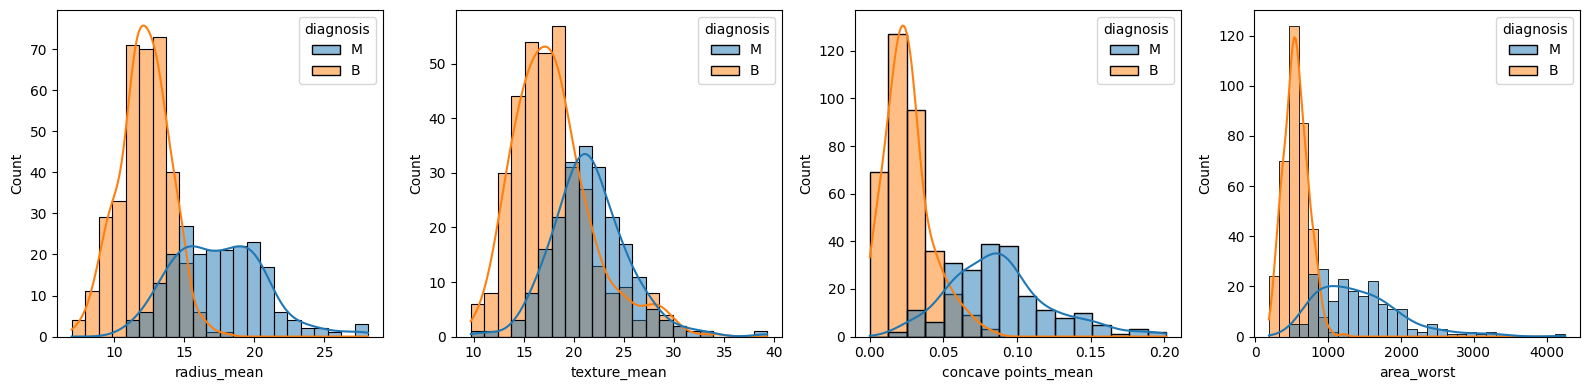

In [6]:
# 4 colunas para ver como os valores se distribuem: tamanho (raio e área), textura e concavidade.
cols = ['radius_mean', 'texture_mean', 'concave points_mean', 'area_worst']  # colunas escolhidas
# subplots(1, 4) cria 1 linha com 4 gráficos. figsize=(16, 4) é o tamanho em polegadas: 16 de largura, 4 de altura.
fig, axes = plt.subplots(1, 4, figsize=(16, 4))                # fig = a figura toda; axes = os 4 gráficos
# zip junta as duas listas em pares: (1º gráfico, 1ª coluna), (2º gráfico, 2ª coluna) e assim por diante.
for ax, col in zip(axes, cols):                                # repete o bloco abaixo para cada par
    # histplot desenha um histograma: barras com quantos pacientes caem em cada faixa de valor.
    # hue='diagnosis' pinta cada classe de uma cor. kde=True acrescenta uma curva suave da distribuição.
    # ax=ax diz em qual dos 4 gráficos desenhar.
    sns.histplot(data=dados, x=col, hue='diagnosis', kde=True, ax=ax)  # histograma por classe
# tight_layout ajusta os espaços, para os títulos e os eixos não ficarem uns por cima dos outros.
plt.tight_layout()                                             # ajusta os espaços
# savefig grava a figura num arquivo PNG, na pasta figuras, para usar no relatório.
plt.savefig('figuras/histogramas.png')                         # salva o gráfico
plt.show()                                                     # mostra o gráfico no notebook

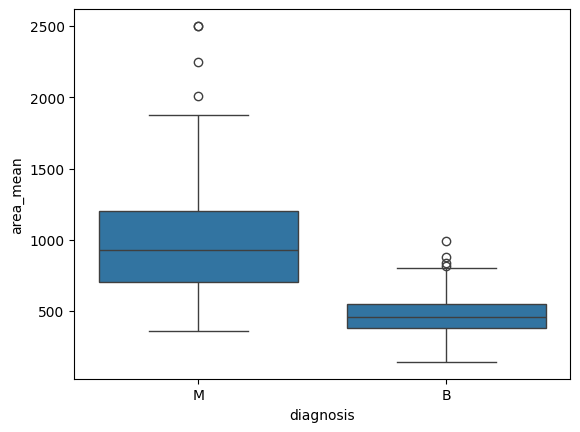

diagnosis              M
radius_mean        27.42
perimeter_mean     186.9
area_mean         2501.0
Name: 461, dtype: object


In [7]:
# boxplot desenha uma caixa por classe. A linha do meio é a mediana; a caixa vai do 1º ao 3º quartil;
# os pontos soltos, fora dos "bigodes", são valores extremos (outliers).
sns.boxplot(data=dados, x='diagnosis', y='area_mean')          # uma caixa para B e outra para M
plt.savefig('figuras/boxplot_area.png')                        # salva o gráfico
plt.show()                                                     # mostra o gráfico
# idxmax devolve a linha do maior valor de area_mean. loc pega essa linha e as colunas escolhidas.
# Raio, perímetro e área grandes ao mesmo tempo: é um tumor grande de verdade, e não um erro de digitação.
print(dados.loc[dados['area_mean'].idxmax(), ['diagnosis', 'radius_mean', 'perimeter_mean', 'area_mean']])  # o maior tumor da base

**O que a exploração mostrou:**

| Achado | Decisão |
| --- | --- |
| 63% benignos e 37% malignos | dividir os dados com `stratify` |
| Malignos têm raio, área e pontos côncavos maiores | as medidas separam bem as classes |
| Escalas muito diferentes (área até 2.501; smoothness perto de 0,1) | padronizar os dados para regressão logística, KNN e SVM |
| Valores extremos são tumores grandes de verdade | manter esses pacientes |

## 3. Limpar e preparar

O modelo só aceita números e não aceita valores vazios. Por isso:

- a coluna `id` sai, porque é só um código;
- a coluna `Unnamed: 32` sai, porque está 100% vazia;
- o alvo vira número com o LabelEncoder (B = 0, M = 1), para que o recall seja calculado para a classe Maligno.

A padronização fica para depois, dentro de um Pipeline, para aprender só com os dados de treino.

In [8]:
# isna() marca com True cada valor vazio (nulo). sum() soma os True de cada coluna: o número de nulos.
nulos = dados.isna().sum()                                     # nulos por coluna
# nulos[nulos > 0] é um filtro: mostra só as colunas com pelo menos 1 nulo.
print(nulos[nulos > 0])                                        # esperado: só 'Unnamed: 32', com 569 nulos (toda vazia)
# drop(columns='id') tira o código do paciente, que é diferente em cada linha e esconderia as repetições.
# duplicated() marca as linhas iguais a uma linha anterior. sum() conta quantas são.
print('Linhas repetidas:', dados.drop(columns='id').duplicated().sum())  # esperado: 0
# drop(columns=[...]) devolve a tabela sem essas colunas. O resultado volta para a variável dados.
dados = dados.drop(columns=['id', 'Unnamed: 32'])              # tira o código do paciente e a coluna vazia
print(dados.shape)                                             # esperado: (569, 31)

Unnamed: 32    569
dtype: int64
Linhas repetidas: 0
(569, 31)


In [9]:
# O LabelEncoder, do scikit-learn, troca texto por número: as categorias viram 0, 1, 2... em ordem alfabética.
from sklearn.preprocessing import LabelEncoder                 # scikit-learn: a biblioteca de Machine Learning
le = LabelEncoder()                                            # cria o codificador, ainda sem saber as categorias
# fit_transform faz 2 coisas: fit aprende as categorias (B e M); transform troca cada uma pelo seu número.
dados['diagnosis'] = le.fit_transform(dados['diagnosis'])      # B vira 0 e M vira 1
# classes_ mostra as categorias na ordem dos números: posição 0 = 'B', posição 1 = 'M'.
print(le.classes_)                                             # esperado: ['B' 'M'], ou seja, maligno = 1
# y é o alvo: o que o modelo deve prever. x são as entradas: as 30 medidas das células.
y = dados['diagnosis']                                         # alvo: 0 = benigno, 1 = maligno
x = dados.drop(columns=['diagnosis'])                          # as 30 colunas de medidas
print(x.shape)                                                 # esperado: (569, 30)
# (x['concavity_mean'] == 0) marca True onde o valor é zero; sum() conta os True.
# Esses zeros são reais (células sem concavidade), não dados faltando. Por isso ficam.
# Os mesmos 13 pacientes, todos benignos, têm zero nas 6 colunas de concavidade.
print('Zeros em concavity_mean:', (x['concavity_mean'] == 0).sum())  # esperado: 13

['B' 'M']
(569, 30)
Zeros em concavity_mean: 13


## 4. Correlação

A correlação mostra quais colunas mais se ligam ao diagnóstico e quais repetem a mesma informação. Vale lembrar que correlação não indica causa.

In [10]:
# corr() calcula a correlação entre todas as colunas, de -1 a 1. Perto de 1: as duas sobem juntas;
# perto de -1: uma sobe e a outra desce; perto de 0: sem relação em linha reta.
# ['diagnosis'] pega só a correlação de cada coluna com o alvo. drop tira o próprio alvo, que daria 1.
# sort_values(ascending=False) ordena do maior para o menor.
corr_alvo = dados.corr()['diagnosis'].drop('diagnosis').sort_values(ascending=False)  # correlação com o diagnóstico
# head(5) pega as 5 primeiras linhas: as 5 maiores correlações.
print(corr_alvo.head(5).round(2))                              # as 5 colunas mais ligadas ao câncer
# abs() tira o sinal (-0,3 vira 0,3). Ordenando do menor para o maior, ficam em cima as mais perto de zero.
print(corr_alvo.abs().sort_values().head(3).round(2))          # as 3 colunas com menos ligação

concave points_worst    0.79
perimeter_worst         0.78
concave points_mean     0.78
radius_worst            0.78
perimeter_mean          0.74
Name: diagnosis, dtype: float64
symmetry_se               0.01
texture_se                0.01
fractal_dimension_mean    0.01
Name: diagnosis, dtype: float64


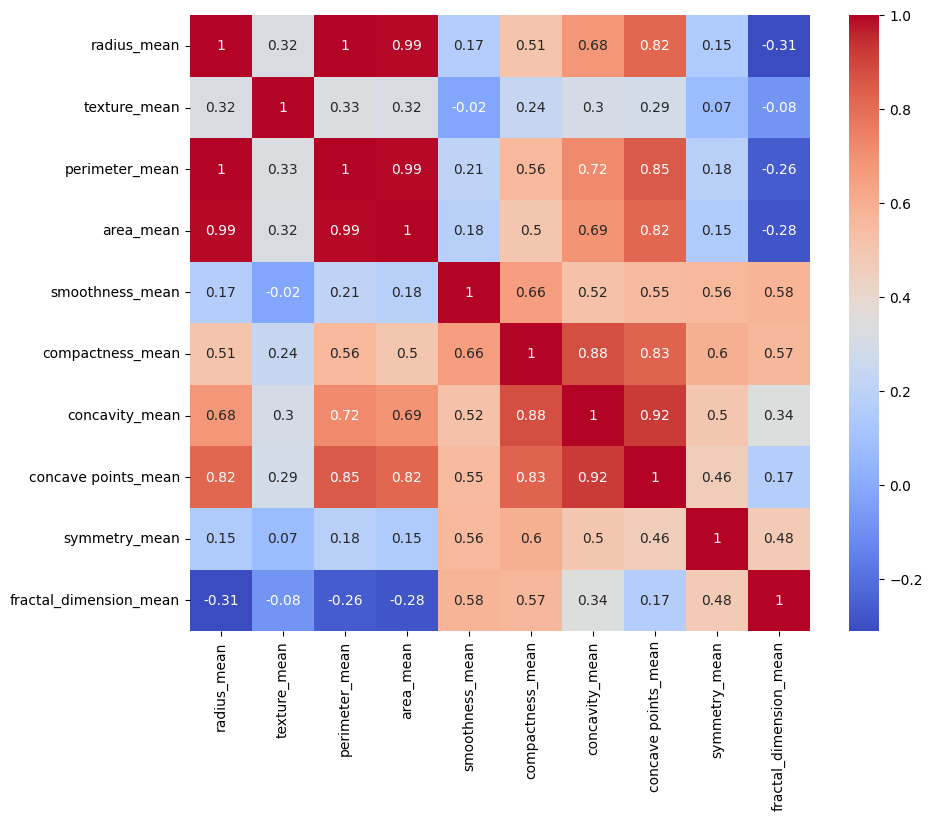

In [11]:
# Esta linha monta uma lista com cada coluna c de x cujo nome termina com '_mean' (list comprehension).
cols_mean = [c for c in x.columns if c.endswith('_mean')]      # as 10 colunas de média
plt.figure(figsize=(10, 8))                                    # nova figura, com 10 x 8 polegadas
# heatmap pinta cada quadrado de uma tabela com uma cor. annot=True escreve o número dentro do quadrado.
# cmap='coolwarm' usa azul para valores negativos e vermelho para positivos. round(2) deixa os números curtos.
sns.heatmap(x[cols_mean].corr().round(2), annot=True, cmap='coolwarm')  # mapa de calor da correlação
# bbox_inches='tight' corta as bordas brancas e não deixa os nomes das colunas cortados na imagem.
plt.savefig('figuras/correlacao_mean.png', bbox_inches='tight')  # salva o gráfico
plt.show()                                                     # mostra o gráfico

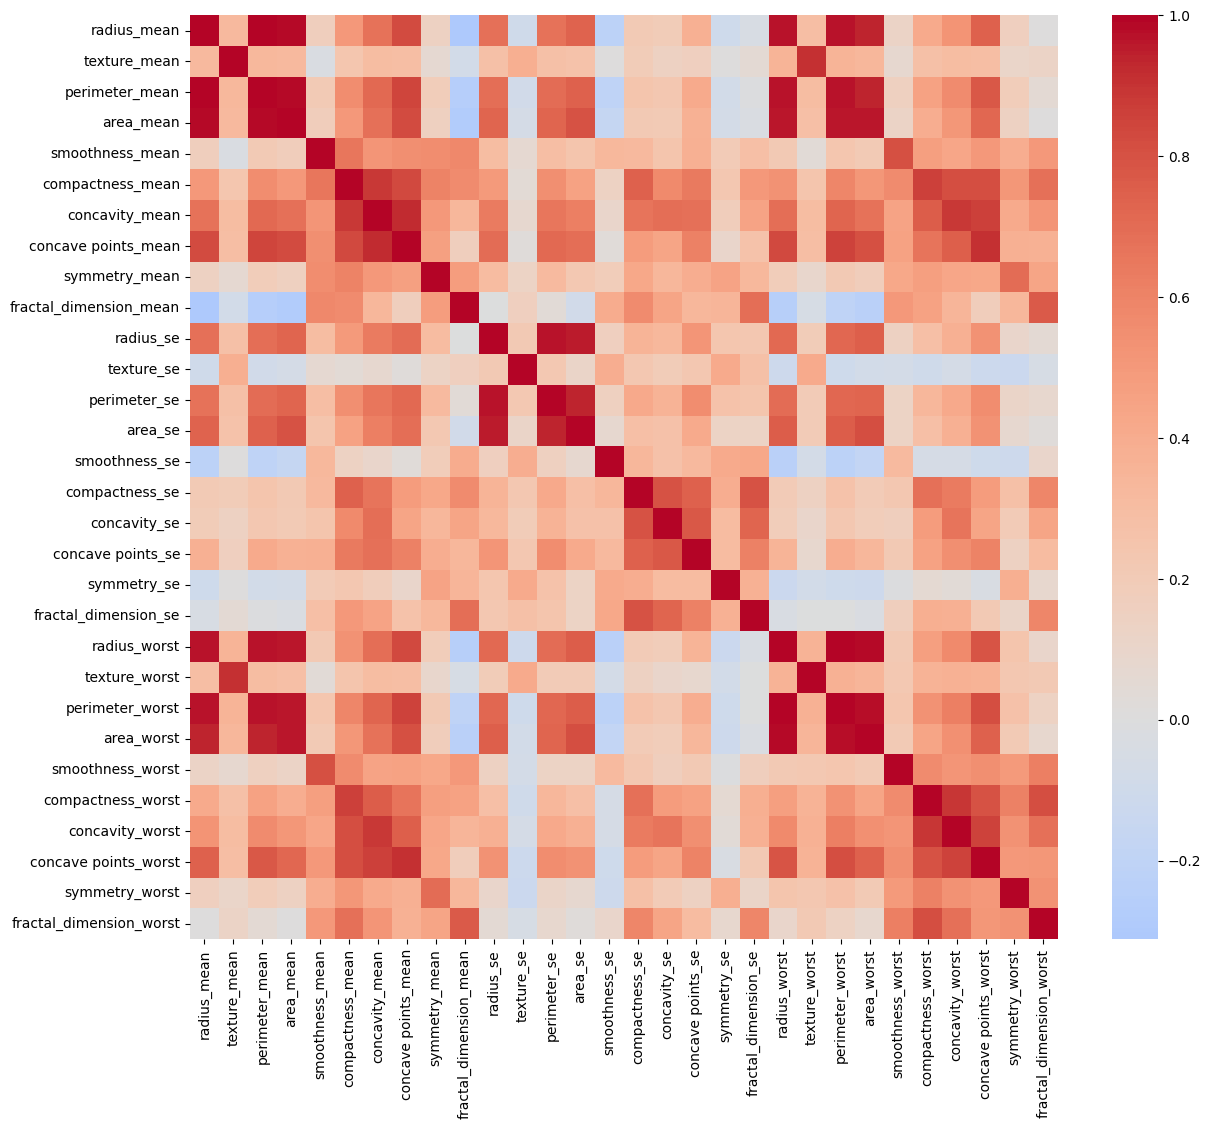

In [12]:
plt.figure(figsize=(14, 12))                                   # figura maior: agora são 30 colunas
# Aqui não há annot: com 30 x 30 quadrados, os números ficariam pequenos demais para ler.
# center=0 põe o zero na cor clara do meio, separando correlações positivas (vermelho) e negativas (azul).
sns.heatmap(x.corr(), cmap='coolwarm', center=0)               # mapa de calor das 30 colunas
plt.savefig('figuras/correlacao_todas.png', bbox_inches='tight')  # salva o gráfico
plt.show()                                                     # mostra o gráfico

In [13]:
# abs() tira o sinal: para achar colunas repetidas, tanto faz se a relação é positiva ou negativa.
c = x.corr().abs()                                             # tabela 30 x 30 de correlações, sem sinal
# Esta lista guarda os pares de colunas com correlação acima de 0,9, no formato (coluna 1, coluna 2, valor).
# c.loc[a, b] lê o valor da linha a e da coluna b. float e round(..., 3) deixam um número simples, com 3 casas.
pares = [(a, b, round(float(c.loc[a, b]), 3))                  # cada par encontrado
         # enumerate dá a posição i de cada coluna a.
         for i, a in enumerate(c.columns)                      # percorre as colunas
         # c.columns[i + 1:] pega só as colunas depois de a. Assim, o par a-b não é contado de novo como b-a.
         for b in c.columns[i + 1:]                            # percorre as colunas seguintes
         # 0,9 é um limite comum para dizer que duas colunas carregam quase a mesma informação.
         if c.loc[a, b] > 0.9]                                 # fica só o par acima de 0,9
# len conta os itens de uma lista.
print('Pares acima de 0,9:', len(pares))                       # esperado: 21
# sorted ordena a lista. key=lambda p: -p[2] ordena pelo valor (3º item do par), do maior para o menor.
# [:3] pega os 3 primeiros.
print(sorted(pares, key=lambda p: -p[2])[:3])                  # os 3 pares mais parecidos; o 1º é raio x perímetro, com 0,998

Pares acima de 0,9: 21
[('radius_mean', 'perimeter_mean', 0.998), ('radius_worst', 'perimeter_worst', 0.994), ('radius_mean', 'area_mean', 0.987)]


## 5. Treino, validação e teste

O modelo precisa ser medido com pacientes que ele nunca viu. Por isso, os dados têm três papéis:

| Parte | Linhas | Para quê |
| --- | --- | --- |
| Teste | 114 (20%) | fica guardado e só é usado no fim, depois de todas as escolhas |
| Treino | 455 (80%) | o modelo aprende |
| Validação | dentro do treino | validação cruzada em 5 partes (KFold), repetida com 10 sorteios diferentes, para comparar modelos e escolher o limiar |

Usamos a validação cruzada, e não um bloco fixo de validação, porque a base é pequena. Um bloco fixo teria só uns 90 pacientes, e o resultado dependeria da sorte.

O KFold sorteia as 5 partes sem olhar a classe, como na 1ª versão do trabalho. Por isso, a proporção de malignos muda um pouco de uma parte para outra (a célula abaixo mostra). Isso pesa pouco: em cada sorteio, todos os 455 pacientes do treino recebem uma chance, então os 170 malignos sempre entram na conta. Repetir o sorteio 10 vezes diminui ainda mais o efeito da sorte. O StratifiedKFold também seria uma escolha válida.

A exploração das seções 2 a 4 usou os 569 pacientes. Ela só guiou escolhas gerais, como estratificar, padronizar e testar o PCA. O modelo, o C e o limiar saem só da validação.

In [14]:
# train_test_split sorteia quais linhas vão para o treino e quais vão para o teste.
# KFold divide o treino em partes, para a validação cruzada.
from sklearn.model_selection import train_test_split, KFold    # ferramentas de divisão dos dados
x_train, x_test, y_train, y_test = train_test_split(           # devolve 4 partes: entradas e alvo, de treino e de teste
    x, y,                                                      # as entradas e o alvo
    test_size=0.2,                                             # 20% das linhas vão para o teste (114 pacientes)
    # stratify=y mantém a mesma proporção de malignos (37%) no treino e no teste.
    stratify=y,                                                # sem isso, o sorteio poderia deixar o teste com poucos malignos
    # random_state fixa o sorteio: com o mesmo número, a divisão sai igual toda vez. O 42 é só uma convenção.
    random_state=42)                                           # resultados repetíveis
# KFold(n_splits=5) divide o treino em 5 partes. Em cada uma das 5 rodadas, 4 partes treinam e 1 valida.
# shuffle=True embaralha as linhas antes de dividir; random_state=42 fixa esse embaralhamento.
kfold = KFold(n_splits=5, shuffle=True, random_state=42)       # a validação cruzada
print(x_train.shape, x_test.shape)                             # esperado: (455, 30) (114, 30)
# y_test tem 0 e 1. A soma conta os 1, ou seja, os malignos do teste.
print('Malignos no teste:', y_test.sum())                      # esperado: 42
# split devolve as posições de treino e de validação de cada rodada; v são as de validação.
# mean dá a proporção de malignos (1) nessa parte. float e round deixam um número simples, com 2 casas.
print('Malignos em cada parte:', [round(float(y_train.iloc[v].mean()), 2) for _, v in kfold.split(x_train)])  # esperado: de 0.33 a 0.43

(455, 30) (114, 30)
Malignos no teste: 42
Malignos em cada parte: [0.35, 0.43, 0.33, 0.42, 0.34]


## 6. Comparar 5 modelos

Comparamos cinco modelos de classificação na validação, sem tocar no teste:

| Modelo | Como decide |
| --- | --- |
| Regressão logística | dá um peso a cada coluna, soma tudo e transforma a soma numa chance |
| KNN | pela classe dos pacientes mais parecidos |
| SVM | pela fronteira com a maior margem entre as classes |
| Árvore de Decisão | por regras do tipo "se / senão" |
| Random Forest | pelo voto de muitas árvores |

Regressão logística, KNN e SVM usam somas ou distâncias e precisam de dados na mesma escala, então vão num Pipeline com StandardScaler. A Árvore e o Random Forest não precisam de escala.

**Como medimos:** cada modelo dá uma **chance de câncer** para cada paciente. Na validação cruzada, a chance de cada paciente do treino vem de um modelo que não o viu. Com essas chances, testamos 1.001 limiares (de 0 a 1) e ficamos com o de **menor custo** (seção 1). Repetimos a validação cruzada com **10 sorteios** diferentes das 5 partes e usamos a média, para o resultado não depender da sorte de um sorteio.

In [15]:
from sklearn.pipeline import Pipeline                          # Pipeline: junta etapas (escala + modelo) num só objeto
from sklearn.preprocessing import StandardScaler               # StandardScaler: deixa cada coluna com média 0 e desvio padrão 1
from sklearn.linear_model import LogisticRegression            # Regressão logística: dá um peso a cada coluna e transforma a soma numa chance
from sklearn.neighbors import KNeighborsClassifier             # KNN: decide pela classe dos pacientes mais parecidos
from sklearn.svm import SVC                                    # SVM: procura a fronteira com a maior margem entre as classes
from sklearn.tree import DecisionTreeClassifier                # Árvore de Decisão: regras do tipo "se / senão"
from sklearn.ensemble import RandomForestClassifier            # Random Forest: o voto de muitas árvores
# cross_val_predict faz a validação cruzada e devolve a previsão de cada paciente do treino,
# feita pelo modelo da rodada em que ele ficou de fora.
from sklearn.model_selection import cross_val_predict          # previsões da validação cruzada

PESO = 10                                                      # regra do grupo (seção 1): perder 1 câncer custa o mesmo que 10 alarmes falsos
# range(42, 52) gera os números de 42 a 51: são 10 sorteios diferentes das 5 partes do KFold.
# O primeiro (42) é o mesmo kfold da célula anterior.
sementes = range(42, 52)                                       # os 10 sorteios
# linspace cria 1.001 limiares igualmente espaçados: 0; 0,001; 0,002; ...; 1.
limiares = np.linspace(0, 1, 1001)                             # os limiares testados

# "def" cria uma função: um bloco de código com nome, que pode ser usado várias vezes.
def chances_validacao(modelo):                                 # devolve as chances de câncer da validação, nos 10 sorteios
    # Para cada sorteio s, a validação cruzada dá a chance de câncer de cada paciente do treino.
    # method='predict_proba' devolve as chances; [:, 1] pega a coluna da chance de maligno.
    return [cross_val_predict(modelo, x_train, y_train,        # só o treino: o teste fica guardado
                              cv=KFold(n_splits=5, shuffle=True, random_state=s),  # as 5 partes deste sorteio
                              method='predict_proba')[:, 1]    # chance de maligno de cada paciente
            for s in sementes]                                 # repete para os 10 sorteios e junta tudo numa lista

def contar(chances):                                           # conta os erros de cada limiar, na média dos 10 sorteios
    malignos = y_train.values == 1                             # True nas linhas dos 170 malignos do treino
    # Num maligno, chance abaixo do limiar = câncer perdido. Num benigno, chance igual ou acima = alarme falso.
    # [:, None] deixa as chances em pé (uma coluna), para comparar cada paciente com os 1.001 limiares de uma vez.
    # sum(axis=0) soma por limiar. np.mean(..., axis=0) faz a média dos 10 sorteios. ~ quer dizer "não".
    perdidos = np.mean([(c[malignos][:, None] < limiares).sum(axis=0) for c in chances], axis=0)  # perdidos por limiar
    alarmes = np.mean([(c[~malignos][:, None] >= limiares).sum(axis=0) for c in chances], axis=0)  # alarmes por limiar
    return perdidos, alarmes                                   # duas listas com 1.001 números cada

def melhor_limiar(perdidos, alarmes, peso=PESO):               # acha o limiar de menor custo
    custo = peso * perdidos + alarmes                          # custo de cada limiar
    i = np.argmin(custo)                                       # argmin devolve a posição do menor valor
    return limiares[i], perdidos[i], alarmes[i], custo[i]      # o limiar e os números dele

# Dicionário {nome: modelo}, com os ajustes padrão. No Pipeline, a escala aprende a média e o desvio
# só com as partes de treino de cada rodada: a parte de validação nunca influencia a padronização.
modelos = {                                                    # os 5 modelos
    # max_iter=5000: mais passos para o ajuste dos pesos terminar sem aviso.
    'Regressão logística': Pipeline([('escala', StandardScaler()), ('modelo', LogisticRegression(max_iter=5000))]),  # usa somas: precisa de escala
    'KNN': Pipeline([('escala', StandardScaler()), ('modelo', KNeighborsClassifier())]),  # usa distâncias: precisa de escala
    # probability=True faz o SVM dar chances, e não só a classe. random_state=42 fixa os sorteios internos.
    'SVM': Pipeline([('escala', StandardScaler()), ('modelo', SVC(probability=True, random_state=42))]),  # também usa distâncias
    'Árvore': DecisionTreeClassifier(random_state=42),         # olha uma coluna por vez: não precisa de escala
    'Random Forest': RandomForestClassifier(random_state=42),  # feito de árvores: também não precisa
}                                                              # fim do dicionário

linhas = []                                                    # lista vazia: vai guardar uma linha de resultado por modelo
curvas = {}                                                    # dicionário vazio: guarda as curvas de cada modelo, para testar outros pesos na seção 7
for nome, modelo in modelos.items():                           # items() devolve os pares (nome, modelo); repete para cada modelo
    perdidos, alarmes = contar(chances_validacao(modelo))      # erros médios em cada limiar
    curvas[nome] = (perdidos, alarmes)                         # guarda as curvas deste modelo
    limiar, p, a, custo = melhor_limiar(perdidos, alarmes)     # o limiar de menor custo deste modelo
    # float tira o formato do NumPy; round deixa 3 casas no limiar e 1 casa no resto (médias de 10 sorteios).
    linhas.append({'modelo': nome,                             # append acrescenta uma linha à lista
                   # limiares[500] é 0,5: o limiar padrão, para comparar.
                   'perdidos com 0,5': round(float(perdidos[500]), 1),  # cânceres perdidos com o limiar padrão
                   'alarmes com 0,5': round(float(alarmes[500]), 1),  # alarmes falsos com o limiar padrão
                   'limiar de menor custo': round(float(limiar), 3),  # o melhor limiar deste modelo
                   'perdidos': round(float(p), 1), 'alarmes': round(float(a), 1),  # erros com o melhor limiar
                   'custo': round(float(custo), 1)})           # 10 x perdidos + alarmes
# DataFrame transforma a lista em tabela; set_index usa o nome do modelo como rótulo de cada linha.
resultado = pd.DataFrame(linhas).set_index('modelo')           # tabela de resultados
# sort_values ordena do menor custo para o maior. Por ser a última linha da célula, o Colab mostra a tabela.
resultado.sort_values('custo')                                 # perdidos: de 170 malignos; alarmes: de 285 benignos

,"perdidos com 0,5","alarmes com 0,5",limiar de menor custo,perdidos,alarmes,custo
modelo,,,,,,
Regressão logística,8.1,3.5,0.097,2.3,28.6,51.6
SVM,7.2,7.8,0.127,3.1,21.6,52.6
Random Forest,10.2,8.1,0.271,4.0,22.5,62.5
KNN,14.7,2.3,0.001,3.1,41.4,72.4
Árvore,16.7,17.8,0.001,16.7,17.8,184.8


**Leitura:** a regressão logística teve o menor custo (51,6), quase igual ao SVM (52,6). Com o limiar de menor custo, ela perde em média 2,3 dos 170 cânceres do treino e dá 28,6 alarmes falsos em 285 benignos. O Random Forest perde mais cânceres no limiar de menor custo (custo 62,5), e a Árvore sozinha é a pior. A coluna do limiar 0,5 mostra por que o limiar importa: com ele, os modelos perdem de 7 a 17 cânceres.

No KNN e na Árvore, o limiar de 0,001 quer dizer pouco. A Árvore só dá chance 0 ou 1, então qualquer limiar acima de 0 dá o mesmo resultado. O KNN só dá chances de 0; 0,2; 0,4 e assim por diante (a parte dos 5 vizinhos que é maligna). Com 0,001, basta 1 vizinho maligno.

**Regressão logística ou SVM?** No custo, os dois empatam: a diferença é de só 1 ponto, e com outros sorteios das 5 partes o SVM fica na frente muitas vezes. Ou seja, é um **empate técnico**. Mas, no nosso caso, a **regressão logística** é a melhor escolha, por dois motivos:

- **Ela perde menos cânceres**, o erro que o grupo considera mais grave. No limiar escolhido pela regra do grupo (peso 10), ela perde 2,3 dos 170 cânceres, e o SVM perde 3,1. O SVM só empata no custo porque dá menos alarmes falsos (21,6 contra 28,6). Com outros sorteios, isso se repete.
- **Ela é mais simples de explicar.** Cada coluna tem um peso, que mostra a direção e a força dela. O SVM que usamos não tem um peso por coluna.

### Teste extra: o PCA ajuda?

A base tem 21 pares de colunas que repetem informação. O PCA junta essas colunas em poucos componentes. Testamos se isso melhora a regressão logística.

In [16]:
from sklearn.decomposition import PCA                          # PCA: resume muitas colunas parecidas em poucas componentes
# Pipeline com 3 etapas, nesta ordem: escala, PCA e regressão logística. O PCA precisa da escala antes;
# sem ela, as colunas com números grandes (como a área) dominariam as componentes.
lr_pca = Pipeline([('escala', StandardScaler()),               # 1ª etapa: padronização
                   # n_components=0.95: o PCA guarda as componentes necessárias para manter 95% da informação (variância).
                   ('pca', PCA(n_components=0.95)),            # 2ª etapa: redução de colunas
                   ('modelo', LogisticRegression(max_iter=5000))])  # 3ª etapa: a mesma regressão logística, para a comparação ser justa
perdidos_pca, alarmes_pca = contar(chances_validacao(lr_pca))  # a mesma validação repetida, agora com PCA
custo_pca = melhor_limiar(perdidos_pca, alarmes_pca)[3]        # [3] pega o 4º valor devolvido: o custo
# fit treina o Pipeline com todo o treino. Aqui, serve só para descobrir quantas componentes o PCA escolheu.
lr_pca.fit(x_train, y_train)                                   # treina
print('Componentes:', lr_pca.named_steps['pca'].n_components_) # esperado: 10 (eram 30 colunas)
print('Custo sem PCA:', resultado.loc['Regressão logística', 'custo'])  # loc pega a linha e a coluna pelo nome. Esperado: 51,6
print('Custo com PCA:', round(float(custo_pca), 1))            # esperado: 60,0

Componentes: 10
Custo sem PCA: 51.6
Custo com PCA: 60.0


**Decisão:** o modelo final **não** usa PCA. O custo ficou maior (60,0 contra 51,6), e as colunas originais são mais fáceis de explicar ao médico.

## 7. Ajustar a regressão logística

Os 5 modelos foram comparados com os ajustes padrão. Só a escolhida, a regressão logística, foi ajustada depois. Um SVM ajustado poderia ter um custo um pouco menor, mas a escolha já foi feita pelos dois motivos da seção 6.

O principal ajuste da regressão logística é o **C**. Ele controla quanto o modelo segue os dados de treino: C pequeno deixa os pesos menores e o modelo mais simples; C grande deixa o modelo seguir mais o treino, com risco de decorar.

O GridSearchCV mede cada ajuste com o limiar fixo de 0,5. Aqui, o limiar também é escolhido, então fazemos a busca com a mesma régua da seção 6: para cada C, a validação repetida e o limiar de menor custo.

In [17]:
linhas_c = []                                                  # uma linha da tabela por valor de C
melhor = None                                                  # None quer dizer "ainda não achou"
for C in [0.01, 0.1, 1, 10, 100]:                              # os valores de C testados, cada um 10 vezes maior que o anterior
    modelo = Pipeline([('escala', StandardScaler()),           # a mesma escala de antes
                       ('modelo', LogisticRegression(C=C, max_iter=5000))])  # a regressão logística com este C
    perdidos, alarmes = contar(chances_validacao(modelo))      # erros médios em cada limiar
    limiar, p, a, custo = melhor_limiar(perdidos, alarmes)     # o limiar de menor custo
    # float tira o formato do NumPy, para a tabela ficar limpa.
    linhas_c.append({'C': C, 'limiar de menor custo': round(float(limiar), 3),  # o limiar, com 3 casas
                     'perdidos (de 170)': round(float(p), 1),  # cânceres perdidos, média dos 10 sorteios
                     'alarmes (de 285)': round(float(a), 1),   # alarmes falsos, média dos 10 sorteios
                     'custo': round(float(custo), 1)})         # 10 x perdidos + alarmes
    if melhor is None or custo < melhor['custo']:              # é o menor custo até agora?
        melhor = {'C': C, 'limiar': limiar, 'custo': custo,    # guarda o vencedor
                  'perdidos': perdidos, 'alarmes': alarmes}    # e as curvas dele, para a seção 10
display(pd.DataFrame(linhas_c).set_index('C'))                 # display mostra a tabela no meio da célula
C_final = melhor['C']                                          # o C escolhido
limiar_final = float(melhor['limiar'])                         # o limiar escolhido
perdidos_final, alarmes_final = melhor['perdidos'], melhor['alarmes']  # as curvas do modelo escolhido
print('Escolhido: C =', C_final, '| limiar =', round(limiar_final, 3))  # esperado: C = 1 e limiar = 0,097
# E se o peso fosse outro? Recalcula com peso 20 e 50, usando as mesmas curvas. Mostra também o custo do SVM.
for peso in [10, 20, 50]:                                      # o peso do grupo e dois pesos maiores
    l, p, a, c = melhor_limiar(perdidos_final, alarmes_final, peso)  # o limiar de menor custo com este peso
    # O * separa o par (perdidos, alarmes) guardado em curvas['SVM'] em dois valores. [3] pega o custo.
    c_svm = melhor_limiar(*curvas['SVM'], peso)[3]             # o menor custo do SVM com este peso
    # Na f-string, {l:.3f} escreve o número com 3 casas, e {p:.1f}, com 1 casa.
    print(f'Peso {peso}: limiar {l:.3f} | perdidos {p:.1f} de 170 | alarmes {a:.1f} de 285 | custo {c:.1f} (SVM: {c_svm:.1f})')  # esperado: limiar de 0,097, 0,081 e 0,063
# O limiar exato importa pouco: perto dele, o custo quase não muda.
custo_final = PESO * perdidos_final + alarmes_final            # o custo de cada limiar, no modelo escolhido
# limiares[80:201] vai de 0,08 a 0,20. min e max pegam o menor e o maior custo nessa faixa.
print('Custo com limiar de 0,08 a 0,20: de', round(float(custo_final[80:201].min()), 1), 'a', round(float(custo_final[80:201].max()), 1),  # a faixa perto do escolhido
      '| com 0,5:', round(float(custo_final[500]), 1))         # esperado: de 51,6 a 56,2 | com 0,5: 84,5

,limiar de menor custo,perdidos (de 170),alarmes (de 285),custo
C,,,,
0.01,0.324,5.2,14.5,66.5
0.10,0.234,3.6,16.8,52.8
1.00,0.097,2.3,28.6,51.6
10.00,0.107,3.3,21.3,54.3
100.00,0.001,2.1,42.9,63.9


Escolhido: C = 1 | limiar = 0.097
Peso 10: limiar 0.097 | perdidos 2.3 de 170 | alarmes 28.6 de 285 | custo 51.6 (SVM: 52.6)
Peso 20: limiar 0.081 | perdidos 2.0 de 170 | alarmes 32.9 de 285 | custo 72.9 (SVM: 75.6)
Peso 50: limiar 0.063 | perdidos 1.6 de 170 | alarmes 41.0 de 285 | custo 121.0 (SVM: 111.4)
Custo com limiar de 0,08 a 0,20: de 51.6 a 56.2 | com 0,5: 84.5


**Modelo final: regressão logística com C = 1 e limiar de 0,097.** O C = 1 é também o valor padrão do scikit-learn; o C = 0,1 ficou perto (custo 52,8). Um paciente com chance de câncer de 9,7% ou mais vira "maligno" e sobe na fila do médico. Na validação, isso perde em média 2,3 dos 170 cânceres (1,4%) e dá alarme falso para 28,6 dos 285 benignos (10%). Com o limiar padrão de 0,5, seriam 8,1 cânceres perdidos.

**O 0,097 não é um número exato.** Perto dele, o custo quase não muda: de 0,08 a 0,20, fica entre 51,6 e 56,2. Com 0,5, sobe para 84,5. Com outros sorteios das 5 partes, o limiar ficaria entre cerca de 0,07 e 0,10. A mensagem principal é esta: o limiar precisa ser baixo, perto de 0,1.

**E se o peso não fosse 10?** Com peso 20 ou 50, o limiar desceria para 0,081 ou 0,063: de 0,3 a 0,7 câncer perdido a menos, ao custo de 4 a 12 alarmes a mais. O limiar muda pouco com o peso. Já o modelo pode mudar: com peso 50, o SVM passaria na frente (custo 111,4 contra 121,0). Mesmo assim, ficaríamos com a regressão logística, pela facilidade de explicar.

Tudo isso foi decidido **antes** de olhar o teste com o modelo novo.

## 8. Avaliar no teste

O teste mostra como o modelo se sai com pacientes novos. Por isso, com o modelo novo, ele só é usado agora, no fim, depois de todas as escolhas. Olhamos a matriz de confusão, o recall, a precisão, o F1 e a curva ROC.

**Nota de transparência:** este trabalho teve uma 1ª versão. Nela, o modelo era um Random Forest com limiar de 0,5, e o teste mostrou 3 cânceres perdidos em 42 (7%), sem alarme falso. O grupo não achou aceitável perder 3 cânceres em 42, e por isso não seguiu com essa versão. A 1ª versão também mostrou no teste o SVM, uma árvore pequena e o efeito de baixar o limiar (com 0,03, nenhum câncer perdido e 23 alarmes falsos). Foram esses resultados que levaram o grupo a criar a regra de custo da seção 1. Ou seja, o teste já tinha sido visto. Por isso, todas as escolhas novas (modelo, C e limiar) foram feitas só com a validação, e o modelo novo foi avaliado no teste uma única vez, aqui. A 3ª célula de código desta seção refaz o Random Forest antigo, para registro.

              precision    recall  f1-score   support

     Benigno      0.985     0.931     0.957        72
     Maligno      0.891     0.976     0.932        42

    accuracy                          0.947       114
   macro avg      0.938     0.953     0.944       114
weighted avg      0.951     0.947     0.948       114



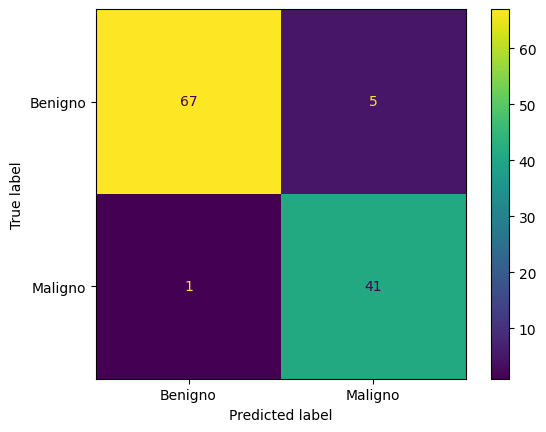

In [18]:
# classification_report: tabela com precisão, recall e F1 de cada classe.
# confusion_matrix conta os acertos e os erros; ConfusionMatrixDisplay desenha essa contagem.
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay  # métricas do teste
final = Pipeline([('escala', StandardScaler()),                # o modelo final: escala + regressão logística
                  ('modelo', LogisticRegression(C=C_final, max_iter=5000))])  # com o C escolhido
final.fit(x_train, y_train)                                    # treina com todo o treino
# predict_proba devolve 2 colunas: a chance de benigno (0) e a de maligno (1). É a primeira vez que o teste é usado.
y_prob = final.predict_proba(x_test)[:, 1]                     # chance de cada paciente do teste ser maligno
# Chance igual ou acima do limiar vira 1 (maligno); abaixo, 0 (benigno). astype(int) troca True e False por 1 e 0.
y_pred = (y_prob >= limiar_final).astype(int)                  # previsões com o limiar escolhido
# target_names dá nome às classes 0 e 1. digits=3 mostra 3 casas decimais.
print(classification_report(y_test, y_pred, target_names=['Benigno', 'Maligno'], digits=3))  # métricas por classe
mc = confusion_matrix(y_test, y_pred)                          # tabela 2 x 2: linhas = classe real, colunas = classe prevista
# plot desenha a matriz. values_format='d' mostra os números como inteiros (72, e não 7.2e+01).
ConfusionMatrixDisplay(confusion_matrix=mc, display_labels=['Benigno', 'Maligno']).plot(values_format='d')  # desenha a matriz
plt.savefig('figuras/matriz_confusao.png')                     # salva o gráfico
plt.show()                                                     # mostra o gráfico

AUC: 0.996


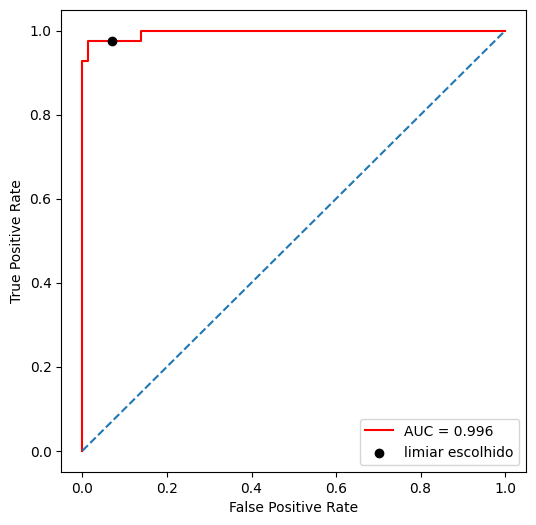

In [19]:
# roc_curve calcula os pontos da curva ROC; auc calcula a área sob essa curva (AUC).
from sklearn.metrics import roc_curve, auc                     # curva ROC e AUC
# Para cada limiar possível, roc_curve calcula a taxa de falsos positivos (fpr) e a de verdadeiros positivos (tpr).
fpr, tpr, _ = roc_curve(y_test, y_prob)                        # pontos da curva; o _ descarta os limiares, que não usamos aqui
roc_auc = auc(fpr, tpr)                                        # a AUC vai de 0,5 (um chute) a 1 (separação perfeita)
print('AUC:', round(roc_auc, 3))                               # a área sob a curva, com 3 casas
# O ponto do limiar escolhido: % de benignos com alarme (x) e % de malignos encontrados (y).
x_ponto = ((y_test == 0) & (y_pred == 1)).sum() / (y_test == 0).sum()  # taxa de falsos positivos no limiar escolhido
y_ponto = ((y_test == 1) & (y_pred == 1)).sum() / (y_test == 1).sum()  # recall no limiar escolhido
plt.figure(figsize=(6, 6))                                     # figura quadrada
plt.plot(fpr, tpr, color='red', label='AUC = %0.3f' % roc_auc) # a curva ROC; '%0.3f' escreve a AUC com 3 casas
plt.plot([0, 1], [0, 1], linestyle='--')                       # linha tracejada: o resultado de um chute ao acaso
# scatter desenha um ponto. zorder=3 põe o ponto na frente das linhas.
plt.scatter([x_ponto], [y_ponto], color='black', zorder=3, label='limiar escolhido')  # onde o modelo opera
plt.xlabel('False Positive Rate')                              # eixo x: taxa de falsos positivos (alarmes falsos)
plt.ylabel('True Positive Rate')                               # eixo y: taxa de verdadeiros positivos (o recall)
plt.legend(loc='lower right')                                  # legenda no canto de baixo, à direita
plt.savefig('figuras/curva_roc.png')                           # salva o gráfico
plt.show()                                                     # mostra o gráfico

In [20]:
# tolist() transforma a matriz em lista, para caber numa linha: [[VN, FP], [FN, VP]].
# V = verdadeiro, F = falso, N = negativo (benigno), P = positivo (maligno).
print('Regressão logística, limiar escolhido:', mc.tolist())   # o resultado da célula anterior
print('Regressão logística, limiar 0,5:', confusion_matrix(y_test, (y_prob >= 0.5).astype(int)).tolist())  # o mesmo modelo, com o limiar padrão
# O modelo da 1ª versão do trabalho, só para registro: Random Forest com 300 árvores e limiar 0,5.
rf_v1 = RandomForestClassifier(n_estimators=300, random_state=42).fit(x_train, y_train)  # fit treina e devolve o próprio modelo
print('Random Forest, limiar 0,5 (1ª versão):', confusion_matrix(y_test, rf_v1.predict(x_test)).tolist())  # esperado: [[72, 0], [3, 39]]

# Overfitting: o modelo vai muito melhor no treino do que com pacientes que não viu?
from sklearn.metrics import recall_score, accuracy_score       # recall e acurácia a partir das respostas reais e previstas
p_treino = (final.predict_proba(x_train)[:, 1] >= limiar_final).astype(int)  # previsões no próprio treino
i = np.argmin(np.abs(limiares - limiar_final))                 # posição do limiar escolhido na lista de limiares
recall_val = 1 - perdidos_final[i] / 170                       # recall na validação: a parte dos 170 malignos que não foi perdida
acuracia_val = 1 - (perdidos_final[i] + alarmes_final[i]) / 455  # acurácia na validação: 455 pacientes no treino
print('Recall:   treino', round(recall_score(y_train, p_treino), 3),  # no treino
      '| validação', round(recall_val, 3), '| teste', round(recall_score(y_test, y_pred), 3))  # na validação e no teste
print('Acurácia: treino', round(accuracy_score(y_train, p_treino), 3),  # no treino
      '| validação', round(acuracia_val, 3), '| teste', round(accuracy_score(y_test, y_pred), 3))  # na validação e no teste

# Incerteza: com só 42 cânceres no teste, quanto a taxa real de cânceres perdidos pode variar?
# Intervalo de confiança de 95% pelo método exato de Clopper-Pearson, que usa a distribuição beta.
from scipy.stats import beta                                   # beta: a distribuição usada no intervalo exato
k = int(((y_test.values == 1) & (y_pred == 0)).sum())          # cânceres perdidos no teste
n = int((y_test.values == 1).sum())                            # total de cânceres no teste
baixo = beta.ppf(0.025, k, n - k + 1) if k > 0 else 0.0        # limite de baixo (0 se nenhum foi perdido)
alto = beta.ppf(0.975, k + 1, n - k) if k < n else 1.0         # limite de cima
# {baixo:.2%} escreve o número como porcentagem, com 2 casas.
print(f'Cânceres perdidos no teste: {k} de {n} | intervalo de 95%: de {baixo:.2%} a {alto:.1%}')  # esperado: de 0,06% a 12,6%

Regressão logística, limiar escolhido: [[67, 5], [1, 41]]
Regressão logística, limiar 0,5: [[71, 1], [3, 39]]


Random Forest, limiar 0,5 (1ª versão): [[72, 0], [3, 39]]
Recall:   treino 0.994 | validação 0.986 | teste 0.976
Acurácia: treino 0.943 | validação 0.932 | teste 0.947
Cânceres perdidos no teste: 1 de 42 | intervalo de 95%: de 0.06% a 12.6%


**Leitura do teste:** o modelo encontrou 41 dos 42 cânceres (recall de 0,976) e deu 5 alarmes falsos em 72 benignos (precisão de 0,891). A AUC de 0,996 mostra que as chances separam bem as classes. Com o limiar de 0,5, o mesmo modelo perderia 3 cânceres, como o Random Forest da 1ª versão.

**Incerteza:** com só 42 cânceres no teste, 1 perdido é pouco para medir a taxa real. O intervalo de confiança de 95% vai de 0,06% a 12,6%.

**Overfitting:** o recall ficou parecido no treino (0,994), na validação (0,986) e no teste (0,976). A acurácia também (0,943; 0,932 e 0,947). Não há sinal de que o modelo decorou o treino. Os números da validação são um pouco otimistas, porque o limiar foi escolhido com eles. Só o teste é uma medida independente.

## 9. Interpretar

O médico precisa entender por que o modelo decide. Usamos duas ferramentas:

- a **importância das variáveis**: na regressão logística, é o peso de cada coluna. Como as colunas foram padronizadas, os pesos podem ser comparados entre si. Peso positivo puxa para maligno; negativo, para benigno;
- o **SHAP**, que explica a decisão de cada paciente (explicado antes das células dele).

texture_worst          1.43
radius_se              1.23
symmetry_worst         1.06
concave points_mean    0.95
concavity_worst        0.91
area_se                0.91
compactness_se        -0.91
area_worst             0.90
radius_worst           0.90
concavity_mean         0.78
dtype: float64
compactness_se: correlação com o diagnóstico 0.28 | com concavity_se 0.81


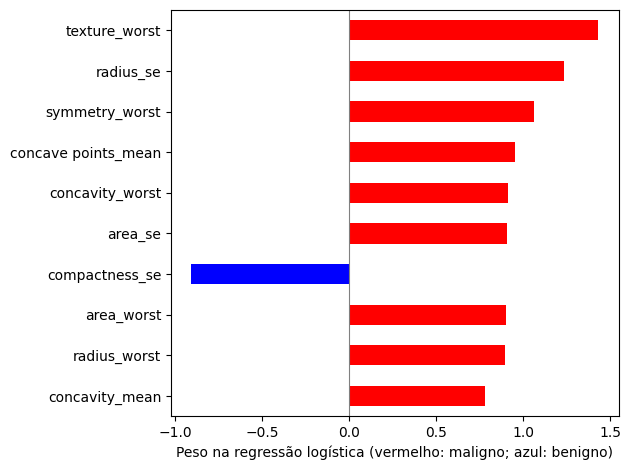

In [21]:
# coef_ guarda os pesos da regressão logística: um por coluna. [0] pega a única linha (há só uma saída: maligno).
# Como as colunas foram padronizadas, os pesos podem ser comparados entre si.
pesos = pd.Series(final.named_steps['modelo'].coef_[0], index=x.columns)  # o peso de cada coluna
# A importância é o tamanho do peso, sem o sinal (abs). sort_values ordena do menor para o maior.
importancia = pesos.abs().sort_values()                        # importância de cada coluna
top10 = pesos[importancia.tail(10).index]                      # os pesos das 10 colunas mais importantes, na ordem crescente de importância
print(top10[::-1].round(2))                                    # [::-1] inverte a ordem: a mais importante em cima
# Por que o compactness_se tem peso negativo? corr calcula a correlação, só no treino.
print('compactness_se: correlação com o diagnóstico', round(x_train['compactness_se'].corr(y_train), 2),  # sozinho, com o câncer
      '| com concavity_se', round(x_train['compactness_se'].corr(x_train['concavity_se']), 2))  # com outra coluna de forma
# Barras horizontais: vermelho = peso positivo (puxa para maligno); azul = negativo (puxa para benigno).
top10.plot.barh(color=['red' if v > 0 else 'blue' for v in top10])  # a lista de cores segue a ordem das barras
plt.axvline(0, color='gray', linewidth=0.8)                    # linha vertical no zero
plt.xlabel('Peso na regressão logística (vermelho: maligno; azul: benigno)')  # nome do eixo x
plt.tight_layout()                                             # ajusta os espaços, para os nomes das colunas caberem
plt.savefig('figuras/feature_importance.png')                  # salva o gráfico
plt.show()                                                     # mostra o gráfico

### SHAP: o que pesou para cada paciente

O peso de uma coluna vale para o modelo todo. Ele não explica **um paciente**: o médico quer saber por que *aquele* exame deu maligno.

O **SHAP** (Lundberg e Lee, 2017) faz isso. Para cada paciente, ele parte da média do modelo e mostra quanto cada coluna somou ou tirou até chegar ao resultado daquele paciente. Na regressão logística, a conta é simples: o SHAP de uma coluna é o **peso dela × quanto o paciente se afasta da média** nessa coluna. Valor positivo empurra para maligno; negativo, para benigno. Os valores ficam na escala interna do modelo (log-odds), que depois vira a chance.

Colunas que repetem informação dividem o peso entre si. Às vezes, uma delas fica até com o sinal trocado, como o `compactness_se` (veja abaixo). Por isso, lemos os **grupos** de colunas (tamanho, concavidade, textura), e não cada coluna sozinha.

Usamos dois gráficos: o **resumo** (todos os pacientes do teste de uma vez) e a **cascata** do caso mais difícil: o câncer do teste com a menor chance (ou o primeiro câncer perdido, se houver).

texture_worst          1.231
radius_se              0.750
symmetry_worst         0.744
concave points_mean    0.700
compactness_se         0.690
dtype: float64


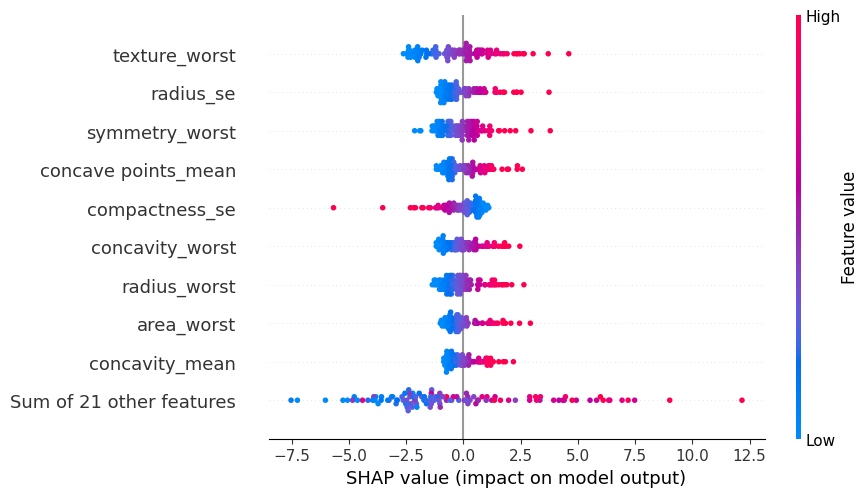

In [22]:
# "!" roda um comando do terminal. O pip instala o SHAP; se ele já estiver instalado (o Colab costuma ter), não faz nada.
!pip install -q shap
import shap                                                    # SHAP: explica cada previsão, coluna por coluna
escala = final.named_steps['escala']                           # a etapa de escala do modelo final
modelo_lr = final.named_steps['modelo']                        # a regressão logística do modelo final
# O treino padronizado serve de referência: é dele que sai a "média" do modelo.
# max_samples=len(x_train) usa os 455 pacientes do treino, sem sortear só uma parte.
referencia = shap.maskers.Independent(escala.transform(x_train), max_samples=len(x_train))  # a referência
# LinearExplainer é o explicador do SHAP para modelos lineares, como a regressão logística.
explicador = shap.LinearExplainer(modelo_lr, referencia)       # explicador do modelo final
bruto = explicador(escala.transform(x_test))                   # valores SHAP dos 114 pacientes do teste
# Explanation junta os valores SHAP com os dados originais (sem padronizar), para os gráficos mostrarem
# as medidas reais de cada paciente e os nomes das colunas.
valores = shap.Explanation(values=bruto.values, base_values=bruto.base_values,  # os valores e a média do modelo
                           data=x_test.values, feature_names=list(x.columns))  # as medidas e os nomes
# np.abs tira o sinal e mean(axis=0) faz a média por coluna: quanto cada coluna pesa, em média, na decisão.
peso_medio = pd.Series(np.abs(valores.values).mean(axis=0), index=x.columns).sort_values(ascending=False)  # peso médio de cada coluna
print(peso_medio.head(5).round(3))                             # as 5 colunas que mais pesam pelo SHAP
# beeswarm (enxame): cada ponto é um paciente. A posição mostra quanto a coluna empurrou a decisão:
# para a direita, maligno; para a esquerda, benigno. A cor mostra o valor da coluna: vermelho = alto, azul = baixo.
# max_display=10 mostra as 10 colunas que mais pesam. show=False deixa o gráfico aberto para salvar antes de mostrar.
shap.plots.beeswarm(valores, max_display=10, show=False)       # gráfico de resumo
plt.savefig('figuras/shap_resumo.png', bbox_inches='tight')    # salva o gráfico
plt.show()                                                     # mostra o gráfico

Cânceres perdidos (posição no teste): [16]
Caso explicado: posição 16 | chance de maligno 0.061 | limiar 0.097


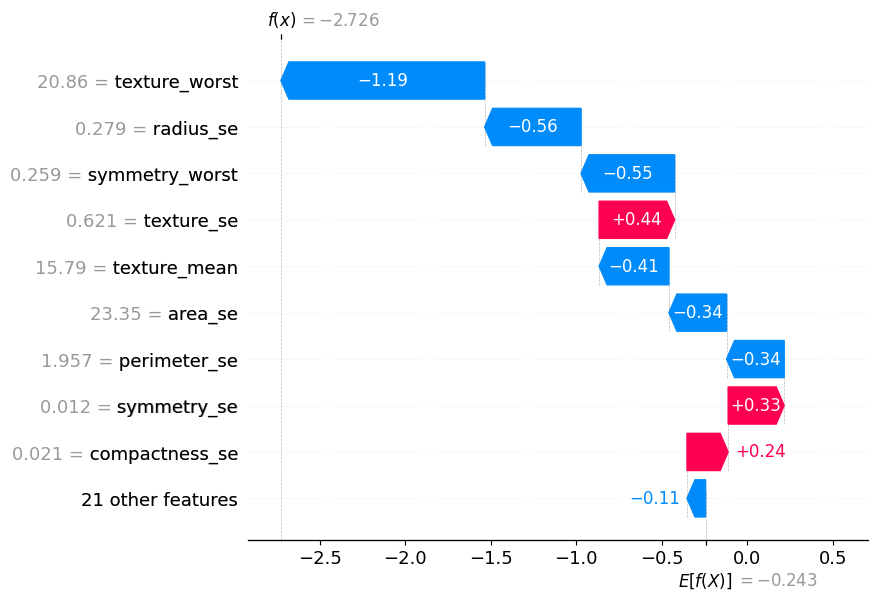

In [23]:
# np.where devolve as posições numa tupla; o [0] tira a lista de posições de dentro dela.
# .values tira os rótulos do pandas, para comparar com y_pred, que é uma lista do NumPy. & quer dizer "e".
malignos_teste = np.where(y_test.values == 1)[0]               # posições dos 42 malignos no teste
perdidos = np.where((y_test.values == 1) & (y_pred == 0))[0]   # posições dos cânceres perdidos
print('Cânceres perdidos (posição no teste):', perdidos)       # lista vazia = nenhum câncer perdido
# O caso mais difícil: o 1º câncer perdido, se houver; senão, o maligno com a menor chance (argmin).
if len(perdidos) > 0:                                          # houve câncer perdido?
    j = perdidos[0]                                            # explica o 1º câncer perdido
else:                                                          # nenhum câncer perdido
    j = malignos_teste[np.argmin(y_prob[malignos_teste])]      # explica o maligno mais perto do limiar
print('Caso explicado: posição', j, '| chance de maligno', round(float(y_prob[j]), 3), '| limiar', round(limiar_final, 3))  # chance e limiar
# waterfall (cascata) explica um paciente. Começa embaixo, em E[f(X)]: a média do modelo, na escala interna (log-odds).
# Cada barra soma (vermelha, para maligno) ou tira (azul, para benigno) a contribuição de uma coluna,
# até chegar em f(x), o resultado deste paciente. Ao lado de cada coluna aparece o valor dela neste paciente.
shap.plots.waterfall(valores[j], max_display=10, show=False)   # cascata do caso mais difícil
plt.savefig('figuras/shap_caso_dificil.png', bbox_inches='tight')  # salva o gráfico
plt.show()                                                     # mostra o gráfico

**Leitura:** os pesos e o SHAP apontam os mesmos grupos de colunas:

- **textura** (`texture_worst`): é a coluna que mais pesa nas duas ferramentas. Textura mais irregular (mais variação nos tons de cinza) empurra para maligno;
- **tamanho** (`radius_se`, `area_se`, `radius_worst`, `area_worst`) e **concavidade** (`concave points_mean`, `concavity_worst`, `concavity_mean`): valores altos empurram para maligno, como na análise de correlação;
- **simetria** (`symmetry_worst`): células menos simétricas empurram para maligno.

O `compactness_se` aparece com peso negativo. Isso não quer dizer que células mais compactas protejam. Sozinha, essa coluna anda junto com o câncer (correlação de 0,28 no treino). Mas ela repete informação de outras colunas de forma, como a `concavity_se` (correlação de 0,81). Com colunas repetidas, o modelo divide o peso entre elas, e uma pode ficar com o sinal trocado. É o efeito das colunas repetidas descrito acima, e por isso lemos os grupos.

**O caso mais difícil:** no teste, o modelo perdeu 1 câncer (posição 16). Ele recebeu chance de 6,1%, abaixo do limiar de 9,7%. Nem com peso 50 (limiar de 0,063) ele seria encontrado. É o mesmo paciente que o Random Forest da 1ª versão também perdia. Na cascata, a maior parte das colunas puxa para benigno: a textura (`texture_worst` = 20,9) é até mais baixa que a média dos benignos do treino (23,7), e a variação do raio (`radius_se` = 0,28) e a simetria (`symmetry_worst` = 0,26) também estão no nível dos benignos. Pelas medidas, esse tumor parece benigno. Por isso, um resultado "benigno" nunca dispensa o exame do médico.

## 10. O preço do limiar: cânceres perdidos × alarmes falsos

O limiar é uma troca: baixar o limiar pega mais cânceres, mas chama mais benignos de malignos. Esta seção mostra o tamanho dessa troca no modelo final, com três limiares: o padrão (0,5), o escolhido pelo custo e o maior limiar que não perde nenhum câncer em nenhum dos 10 sorteios da validação.

Os números da validação são a média dos 10 sorteios. O teste aparece só para conferir: a escolha já foi feita na seção 7.

In [24]:
# O maior limiar que não perde nenhum câncer em nenhum dos 10 sorteios da validação.
# perdidos_final == 0 marca os limiares com zero perdidos; max pega o maior deles.
limiar_zero = float(limiares[perdidos_final == 0].max())       # o limiar do "zero perdidos"
# Com que peso o "zero perdidos" seria o limiar de menor custo? next devolve o 1º peso da lista que faz isso.
peso_zero = next(p for p in range(10, 1001) if melhor_limiar(perdidos_final, alarmes_final, p)[0] <= limiar_zero)  # o menor peso
print('Limiar do "zero perdidos":', limiar_zero, '| peso mínimo para ele ser o de menor custo:', peso_zero)  # esperado: 0,001 e 85
linhas_limiar = []                                             # lista vazia: uma linha da tabela por limiar
for nome, limiar in [('padrão', 0.5), ('escolhido (custo)', limiar_final), ('zero perdidos na validação', limiar_zero)]:  # os 3 limiares
    i = np.argmin(np.abs(limiares - limiar))                   # posição deste limiar na lista
    linhas_limiar.append({'limiar': nome, 'valor': round(limiar, 3),  # o nome e o valor do limiar
                          # Na validação: média dos 10 sorteios.
                          'perdidos na validação (de 170)': round(float(perdidos_final[i]), 1),  # cânceres perdidos
                          'alarmes na validação (de 285)': round(float(alarmes_final[i]), 1),  # alarmes falsos
                          # No teste: chance abaixo do limiar num maligno = perdido; igual ou acima num benigno = alarme.
                          'perdidos no teste (de 42)': int(((y_test.values == 1) & (y_prob < limiar)).sum()),  # cânceres perdidos
                          'alarmes no teste (de 72)': int(((y_test.values == 0) & (y_prob >= limiar)).sum())})  # alarmes falsos
tabela_limiar = pd.DataFrame(linhas_limiar).set_index('limiar')  # set_index usa o nome como rótulo de cada linha
tabela_limiar                                                  # mostra a tabela

Limiar do "zero perdidos": 0.001 | peso mínimo para ele ser o de menor custo: 85


,valor,perdidos na validação (de 170),alarmes na validação (de 285),perdidos no teste (de 42),alarmes no teste (de 72)
limiar,,,,,
padrão,0.500,8.1,3.5,3,1
escolhido (custo),0.097,2.3,28.6,1,5
zero perdidos na validação,0.001,0.0,171.3,0,40


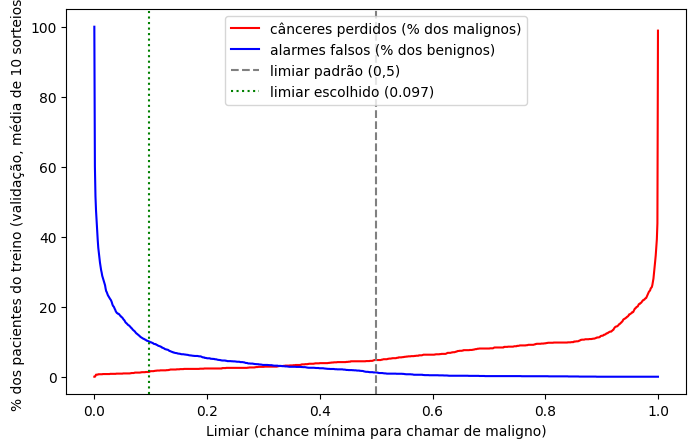

In [25]:
# A curva da troca: para cada limiar, a % de malignos perdidos e a % de benignos com alarme, na validação.
plt.figure(figsize=(8, 5))                                     # figura retangular
plt.plot(limiares, perdidos_final / 170 * 100, color='red', label='cânceres perdidos (% dos malignos)')  # linha vermelha
plt.plot(limiares, alarmes_final / 285 * 100, color='blue', label='alarmes falsos (% dos benignos)')  # linha azul
# axvline desenha uma linha vertical num ponto do eixo x. linestyle='--' faz tracejada; ':' faz pontilhada.
plt.axvline(0.5, color='gray', linestyle='--', label='limiar padrão (0,5)')  # o limiar padrão
plt.axvline(limiar_final, color='green', linestyle=':', label=f'limiar escolhido ({limiar_final:.3f})')  # o limiar escolhido
plt.xlabel('Limiar (chance mínima para chamar de maligno)')    # nome do eixo x
plt.ylabel('% dos pacientes do treino (validação, média de 10 sorteios)')  # nome do eixo y
plt.legend()                                                   # mostra a legenda
plt.savefig('figuras/limiar_tradeoff.png', bbox_inches='tight')  # salva o gráfico
plt.show()                                                     # mostra o gráfico

**Leitura do limiar:**

| Limiar | Cânceres perdidos no teste | Alarmes falsos no teste |
| --- | --- | --- |
| padrão (0,5) | 3 de 42 | 1 de 72 |
| escolhido pelo custo (0,097) | 1 de 42 | 5 de 72 (7%) |
| zero perdidos na validação (0,001) | 0 de 42 | 40 de 72 (56%) |

Com o limiar escolhido, o modelo encontrou 41 dos 42 cânceres (recall de 0,976) e deu 5 alarmes falsos. Isso está perto do esperado pela validação: cerca de 0,6 câncer perdido e 7 alarmes num teste deste tamanho.

**Os primeiros cânceres saem baratos; os últimos, caros.** Na validação, descer o limiar de 0,5 para 0,097 evita cerca de 6 dos 8 cânceres perdidos, ao custo de 25 alarmes: cerca de 4 alarmes por câncer. Para não perder nenhum, o limiar teria de cair para 0,001, com alarme para 60% dos benignos: cerca de 62 alarmes para cada câncer a mais.

**Por que não usamos o "zero perdidos"?** A regra do grupo diz que um câncer vale **pelo menos** 10 alarmes. Mas, mesmo com peso 50, o limiar de menor custo seria 0,063, e não 0,001 (seção 7). O "zero perdidos" só seria o de menor custo se um câncer valesse 85 alarmes ou mais (a célula da tabela mostra esse número). Além disso, nem esse limiar garantiria zero cânceres perdidos em pacientes novos.

## 11. Discussão crítica

O modelo pode apoiar a triagem, mas não substitui o médico.

**Como usar na prática:** o modelo entra depois do exame e antes da consulta. Ele mostra a chance de câncer e as medidas que mais pesaram. Quem passa do limiar sobe na fila do médico. Um resultado "benigno" nunca dispensa o paciente: o médico vê todos os exames e decide.

**Limites:**

- O modelo perdeu 1 dos 42 cânceres do teste (2,4%). Com só 42 cânceres, a taxa real em pacientes novos pode ser maior: o intervalo de confiança de 95% (método exato de Clopper-Pearson, seção 8) vai até cerca de 13%.
- O limiar baixo traz alarmes falsos: no teste, 5 de 72 benignos (7%) seriam chamados para mais exames.
- Na base, 37% dos nódulos são malignos. No hospital, essa proporção pode ser outra. Com menos cânceres, haveria mais alarmes para cada câncer encontrado, e a precisão cairia. Por isso, o limiar precisa ser revisto com dados do hospital.
- A base é pequena (569 pacientes) e vem de um único centro nos EUA. O modelo e o limiar precisam ser testados com pacientes do hospital antes do uso, e o limiar deve ser revisto com a equipe médica.

## 12. Baixar as figuras

O Colab apaga os arquivos quando a sessão fecha. Esta célula junta as figuras num .zip, para o GitHub e o relatório.

In [26]:
import shutil                                                  # shutil: copia, move e compacta arquivos
# make_archive cria o arquivo figuras_parteA.zip com tudo o que está na pasta figuras.
shutil.make_archive('figuras_parteA', 'zip', 'figuras')        # junta os gráficos num .zip
# sys.modules lista as bibliotecas carregadas. 'google.colab' só aparece quando o notebook roda no Colab.
if 'google.colab' in sys.modules:                              # só no Colab (no Docker, pula)
    from google.colab import files                             # ferramenta de download do Colab
    files.download('figuras_parteA.zip')                       # o navegador baixa o .zip para o seu computador